# 2. GridGuard: protecting a shared AI model

**The idea from our synopsis.** Homes want one shared AI model that splits the meter reading into appliances (this is called **NILM**, Non-Intrusive Load Monitoring). Nobody wants to upload their raw readings, so each home trains the model on its own data and only sends back the *changes* to the model. This is **federated learning**.

The problem is that some homes send strange updates, for three very different reasons:

| Reason | What GridGuard does |
|---|---|
| **Attack**: someone sends a harmful update on purpose | reject it |
| **Broken meter**: stuck, spiking or reversed (like in notebook 1) | quarantine it, without blaming the family |
| **Real change**: new EV or solar panels | accept it, with half weight |

The normal method, **FedAvg**, just averages everything. This notebook trains FedAvg and GridGuard side by side on the same 8 homes and compares them.

In [1]:
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from cryptography.exceptions import InvalidSignature
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from matplotlib.colors import ListedColormap
from torch import nn

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
APPLIANCES = ["fridge", "kettle", "washing_machine"]
SCALES = [200.0, 3000.0, 2500.0]
DAY, WINDOW, WARMUP, ROUNDS = 1440, 59, 3, 8
torch.set_num_threads(4)

## Step 1: the homes

Each home has a fridge, a kettle and a washing machine, plus background load. The function below builds the same kind of one-minute data the Node-RED simulator produces, but for several days at once, and it also keeps the true power of every appliance. Those true values are what the AI learns from, like the plug sensors in public datasets such as UK-DALE.

`add_event` switches on a meter fault (`stuck`, `spike`, `reverse`) or a real change (`ev`, `solar`) from a chosen day.

In [2]:
def block(load, start, length, power):
    start, end = int(start), min(len(load), int(start) + int(length))
    if start < end:
        load[start:end] += power


def make_home(seed, days):
    rng = np.random.default_rng(seed)
    n = days * DAY
    minute = np.arange(n) % DAY
    base = rng.uniform(50, 150) * (1 + 0.05 * np.sin(2 * np.pi * minute / DAY)) + rng.uniform(100, 300) * ((minute > 1050) & (minute < 1380))
    fridge, kettle, washer = np.zeros(n), np.zeros(n), np.zeros(n)
    on, off, t = rng.uniform(15, 22), rng.uniform(30, 45), rng.uniform(0, 60)
    while t < n:
        block(fridge, t, on, rng.uniform(80, 130))
        t += on + off * rng.uniform(0.85, 1.15)
    for day in range(days):
        for _ in range(rng.poisson(4)):
            block(kettle, day * DAY + rng.choice([rng.uniform(380, 540), rng.uniform(960, 1320)]), rng.integers(2, 5), 2500)
        if rng.random() < 0.5:
            t = day * DAY + rng.uniform(480, 1200)
            block(washer, t, 15, 2000)
            block(washer, t + 15, 40, rng.uniform(150, 300))
            block(washer, t + 55, 10, rng.uniform(400, 600))
    total = base + fridge + kettle + washer + rng.normal(0, 2, n)
    home = pd.DataFrame({"aggregate": np.round(np.maximum(total, 0), 1), "fridge": fridge, "kettle": kettle, "washing_machine": washer})
    home.index = pd.date_range("2026-01-05", periods=n, freq="60s")
    return home


def add_event(home, kind, start_day, seed):
    rng = np.random.default_rng(seed)
    x = home["aggregate"].to_numpy(copy=True)
    start = start_day * DAY
    minute = np.arange(len(x)) % DAY
    if kind == "ev":
        for day in range(start_day, len(x) // DAY):
            if rng.random() < 0.8:
                block(x, day * DAY + rng.uniform(1080, 1320), rng.integers(120, 300), 7000)
    elif kind == "solar":
        x[start:] -= 3000 * np.clip(np.sin(np.pi * (minute[start:] - 390) / 720), 0, None)
    elif kind == "spike":
        hits = start + np.flatnonzero(rng.random(len(x) - start) < 0.004)
        x[hits] += rng.uniform(5000, 15000, len(hits))
    elif kind == "stuck":
        t = start
        while t < len(x):
            t += int(rng.integers(100, 400))
            length = int(rng.integers(30, 240))
            x[t : t + length] = x[min(t, len(x) - 1)]
            t += length
    elif kind == "reverse":
        x[start:] = -x[start:]
    changed = home.copy()
    changed["aggregate"] = np.round(x, 1)
    return changed

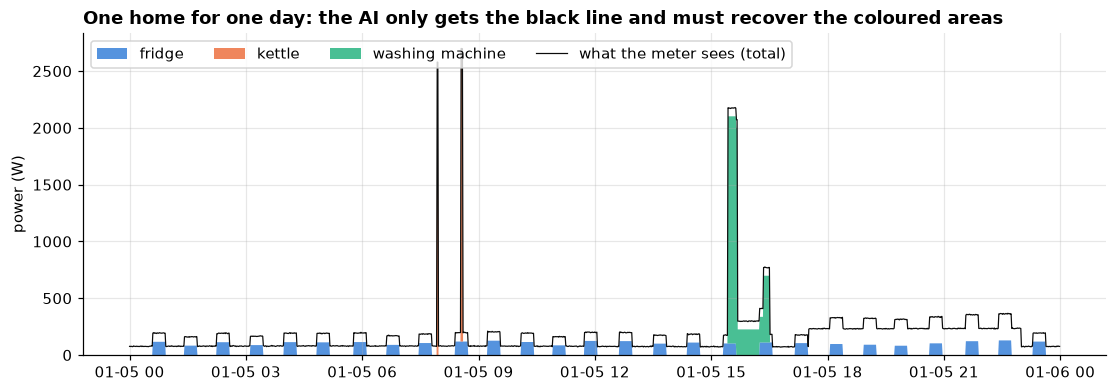

In [3]:
home = make_home(seed=2, days=1)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(home.index, home["fridge"], home["kettle"], home["washing_machine"], labels=["fridge", "kettle", "washing machine"], colors=["#2a78d6", "#eb6834", "#1baf7a"], alpha=0.8)
ax.plot(home.index, home["aggregate"], color="#0b0b0b", lw=0.8, label="what the meter sees (total)")
ax.set_ylabel("power (W)")
ax.legend(loc="upper left", ncol=4)
ax.set_title("One home for one day: the AI only gets the black line and must recover the coloured areas", loc="left", fontweight="bold")
plt.show()

## Step 2: the AI model (Seq2Point)

A small neural network looks at 59 minutes of total power and guesses the fridge, kettle and washing-machine power at the middle minute. Error is measured in watts (mean absolute error) on two test homes that never take part in training.

In [4]:
class Seq2Point(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 16, 9, padding=4), nn.ReLU(),
            nn.Conv1d(16, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 24, 5, padding=2), nn.ReLU(), nn.Flatten(),
            nn.Linear(24 * (WINDOW // 2), 64), nn.ReLU(), nn.Linear(64, len(APPLIANCES)),
        )

    def forward(self, x):
        return self.net(x.unsqueeze(1))


def windows(frame, stride=2):
    total = frame["aggregate"].to_numpy(dtype=np.float32) / 2000
    target = frame[APPLIANCES].to_numpy(dtype=np.float32) / np.array(SCALES, dtype=np.float32)
    starts = np.arange(0, len(total) - WINDOW + 1, stride)
    return torch.tensor(np.lib.stride_tricks.sliding_window_view(total, WINDOW)[starts]), torch.tensor(target[starts + WINDOW // 2])


def load(model, weights):
    with torch.no_grad():
        for param, value in zip(model.parameters(), weights):
            param.copy_(value)


def train_local(weights, frame, seed):
    model = Seq2Point()
    load(model, weights)
    x, y = windows(frame)
    torch.manual_seed(seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(2):
        for batch in torch.randperm(len(x)).split(128):
            optimiser.zero_grad()
            nn.functional.mse_loss(model(x[batch]), y[batch]).backward()
            optimiser.step()
    return [new.detach() - old for new, old in zip(model.parameters(), weights)], len(x)


def error_in_watts(weights, homes):
    model = Seq2Point()
    load(model, weights)
    model.eval()
    with torch.no_grad():
        errors = [((model(x).clamp(min=0) - y).abs() * torch.tensor(SCALES)).mean() for x, y in (windows(h, 1) for h in homes)]
    return float(torch.stack(errors).mean())


print(f"model size: {sum(p.numel() for p in Seq2Point().parameters()):,} numbers")

model size: 48,715 numbers


## Step 3: how GridGuard investigates an update

**a) Evidence from the meter**, computed inside the home. Only these six numbers leave the house, the same ideas Node-RED uses in notebook 1:

In [5]:
def meter_evidence(current, reference):
    x = current.to_numpy(dtype=float)
    minute = current.index.hour.to_numpy() * 60 + current.index.minute.to_numpy()
    run, stuck = 0, 0
    for same in np.diff(x) == 0:
        run = run + 1 if same else 0
        stuck += run >= 9
    level = (np.clip(x, 0, None).mean() + 10) / (np.clip(reference.to_numpy(dtype=float), 0, None).mean() + 10)
    return {
        "spikes": float(np.mean(x[1:-1] - np.maximum(x[:-2], x[2:]) > 4000)),
        "stuck": float(stuck / len(x)),
        "negative_at_night": float(np.mean(x[minute < 240] < -20)),
        "negative_by_day": float(np.mean(x[(minute >= 420) & (minute < 1020)] < -20)),
        "usage_change": float(np.log(level)),
        "heavy_load": float(np.mean(np.convolve(x > 5000, np.ones(60), "valid") >= 60)),
    }

**b) Evidence from the update itself.** `size` compares the update with the typical one (a scaling attack is huge). `direction` measures how similar it is to everyone else's (a sign-flip attack points the opposite way, giving a negative value).

**c) Decision rules.** The meter is checked first, because a broken meter also produces a strange update, and that is not the family's fault.

In [6]:
def update_evidence(updates):
    flat = {cid: torch.cat([w.flatten() for w in u]) for cid, u in updates.items()}
    median = float(np.median([v.norm() for v in flat.values()]))
    result = {}
    for cid, v in flat.items():
        others = torch.stack([o for other, o in flat.items() if other != cid])
        result[cid] = {"size": float(v.norm()) / median, "direction": float(nn.functional.cosine_similarity(v, others.median(dim=0).values, dim=0))}
    return result


def find_cause(meter, update, integrity):
    fault = meter["spikes"] > 0.001 or meter["stuck"] > 0.05 or meter["negative_at_night"] > 0.3
    solar = meter["negative_by_day"] > 0.1 and meter["negative_at_night"] < 0.05
    change = solar or meter["heavy_load"] > 0.01 or abs(meter["usage_change"]) > 0.4
    odd = update["size"] > 3 or update["direction"] < 0 or (integrity < 0.5 and update["direction"] < 0.1)
    if fault:
        return "meter_fault"
    if odd:
        return "uncertain" if change else "malicious"
    return "genuine_change" if change else "benign"

**d) Trust.** Every home has three scores. *Integrity* halves after every attack, and once it drops below 0.25 the home is ignored. *Reliability* drops when the meter is faulty. *Adaptability* grows when a real change is confirmed. The weight of an update in the average depends on these scores.

**e) Signatures and an audit chain.** Each home signs its update with its own Ed25519 key over a SHA-256 fingerprint, so an update changed on the way fails the check. Every decision is written to a hash chain, where each record stores the fingerprint of the previous one.

In [7]:
def update_trust(t, cause):
    if cause == "benign":
        t["integrity"] = min(1.0, t["integrity"] + 0.1 * t["integrity"] * (1 - t["integrity"]) + 0.01)
        t["reliability"] = min(1.0, t["reliability"] + 0.1)
    elif cause in ("malicious", "bad_signature"):
        t["integrity"] *= 0.5
    elif cause == "meter_fault":
        t["reliability"] *= 0.6
    elif cause == "genuine_change":
        t["adaptability"] = min(1.0, t["adaptability"] + 0.1)
    elif cause == "uncertain":
        t["integrity"] *= 0.95


def weight_for(t, cause):
    if t["integrity"] < 0.25:
        return 0.0
    return {"benign": t["integrity"], "genuine_change": 0.5 * t["integrity"] * t["adaptability"]}.get(cause, 0.0)


def signed_message(cid, round_number, update, evidence):
    fingerprint = hashlib.sha256(b"".join(w.numpy().astype("float32").tobytes() for w in update)).hexdigest()
    return json.dumps({"client": cid, "round": round_number, "hash": fingerprint, "evidence": evidence}, sort_keys=True).encode()


def signature_ok(public_key, signature, message):
    try:
        public_key.verify(signature, message)
        return True
    except InvalidSignature:
        return False


class AuditChain:
    def __init__(self):
        self.records = []

    def add(self, entry):
        record = {"index": len(self.records), "entry": entry, "previous": self.records[-1]["hash"] if self.records else "0" * 64}
        record["hash"] = hashlib.sha256(json.dumps(record, sort_keys=True).encode()).hexdigest()
        self.records.append(record)

    def first_broken(self):
        previous = "0" * 64
        for record in self.records:
            body = {k: record[k] for k in ("index", "entry", "previous")}
            if record["previous"] != previous or hashlib.sha256(json.dumps(body, sort_keys=True).encode()).hexdigest() != record["hash"]:
                return record["index"]
            previous = record["hash"]
        return None

## Step 4: the neighbourhood

Eight homes. Some attack, some have broken meters, and some genuinely change. Events start in the round shown.

In [8]:
SCENARIO = {
    "house-01": ("attack", "sign_flip", 3),
    "house-02": ("attack", "scaling", 3),
    "house-03": ("fault", "stuck", 3),
    "house-04": ("fault", "reverse", 4),
    "house-05": ("change", "ev", 3),
    "house-06": ("change", "solar", 4),
    "house-07": ("attack", "tamper", 5),
}
TRUTH = {"attack": "malicious", "fault": "meter_fault", "change": "genuine_change"}

homes = {}
for i in range(8):
    cid = f"house-{i:02d}"
    frame = make_home(i, WARMUP + ROUNDS)
    category, kind, start = SCENARIO.get(cid, (None, None, 1))
    if category in ("fault", "change"):
        frame = add_event(frame, kind, WARMUP + start - 1, i)
    homes[cid] = {"frame": frame, "category": category, "kind": kind, "start": start, "key": Ed25519PrivateKey.generate()}
test_homes = [make_home(900 + i, 2) for i in range(2)]
pd.DataFrame([{"home": cid, "event": f"{h['category']}: {h['kind']}" if h["category"] else "normal", "from round": h["start"] if h["category"] else "-"} for cid, h in homes.items()])

,home,event,from round
0,house-00,normal,-
1,house-01,attack: sign_flip,3
2,house-02,attack: scaling,3
3,house-03,fault: stuck,3
4,house-04,fault: reverse,4
5,house-05,change: ev,3
6,house-06,change: solar,4
7,house-07,attack: tamper,5


## Step 5: train FedAvg and GridGuard side by side

In every round each home trains on its last two days of data. An attacker then distorts its update: **sign flip** sends −5× its update, **scaling** sends 20×, and **tampering** changes the update after it was signed, like a hacker on the network. Both servers receive exactly the same kind of updates.

In [9]:
def client_round(cid, weights, r):
    h = homes[cid]
    data = h["frame"].iloc[(WARMUP + r - 2) * DAY : (WARMUP + r) * DAY]
    evidence = meter_evidence(data["aggregate"], h["frame"]["aggregate"].iloc[: 2 * DAY])
    update, samples = train_local(weights, data, seed=r * 100 + int(cid[-2:]))
    attacking = h["category"] == "attack" and r >= h["start"]
    if attacking and h["kind"] == "sign_flip":
        update = [-5 * u for u in update]
    if attacking and h["kind"] == "scaling":
        update = [20 * u for u in update]
    signature = h["key"].sign(signed_message(cid, r, update, evidence))
    if attacking and h["kind"] == "tamper":
        update = [update[0] + 0.01] + update[1:]
    return {"cid": cid, "update": update, "samples": samples, "evidence": evidence, "signature": signature}


def average(weights, updates, factors):
    total = sum(factors)
    if total == 0:
        return weights
    return [w + sum(f * u[i] for u, f in zip(updates, factors)) / total for i, w in enumerate(weights)]


torch.manual_seed(0)
start_weights = [p.detach().clone() for p in Seq2Point().parameters()]
weights = {"FedAvg": start_weights, "GridGuard": [w.clone() for w in start_weights]}
trust = {cid: {"integrity": 1.0, "reliability": 1.0, "adaptability": 0.5} for cid in homes}
chain, history, decisions = AuditChain(), [], []

for r in range(1, ROUNDS + 1):
    fed = [client_round(cid, weights["FedAvg"], r) for cid in homes]
    weights["FedAvg"] = average(weights["FedAvg"], [m["update"] for m in fed], [m["samples"] for m in fed])

    guarded = [client_round(cid, weights["GridGuard"], r) for cid in homes]
    verified = []
    for m in guarded:
        ok = signature_ok(homes[m["cid"]]["key"].public_key(), m["signature"], signed_message(m["cid"], r, m["update"], m["evidence"]))
        if ok:
            verified.append(m)
        else:
            update_trust(trust[m["cid"]], "bad_signature")
            decisions.append({"round": r, "home": m["cid"], "cause": "bad_signature", "weight": 0.0})
    info = update_evidence({m["cid"]: m["update"] for m in verified})
    limit = 2 * np.median([info[m["cid"]]["size"] for m in verified])
    updates, factors = [], []
    for m in verified:
        cause = find_cause(m["evidence"], info[m["cid"]], trust[m["cid"]]["integrity"])
        update_trust(trust[m["cid"]], cause)
        updates.append([u * min(1.0, limit / info[m["cid"]]["size"]) for u in m["update"]])
        factors.append(m["samples"] * weight_for(trust[m["cid"]], cause))
        decisions.append({"round": r, "home": m["cid"], "cause": cause, "weight": factors[-1]})
    weights["GridGuard"] = average(weights["GridGuard"], updates, factors)
    for d in decisions[-len(homes):]:
        chain.add({"round": r, "home": d["home"], "cause": d["cause"]})

    for name in weights:
        history.append({"round": r, "strategy": name, "error_w": error_in_watts(weights[name], test_homes)})
    print(f"round {r}:  FedAvg error {history[-2]['error_w']:7.1f} W    GridGuard error {history[-1]['error_w']:6.1f} W")

round 1:  FedAvg error    42.5 W    GridGuard error   42.5 W


round 2:  FedAvg error    43.0 W    GridGuard error   43.0 W


round 3:  FedAvg error    65.7 W    GridGuard error   36.7 W


round 4:  FedAvg error    64.0 W    GridGuard error   42.5 W


round 5:  FedAvg error   316.0 W    GridGuard error   24.7 W


round 6:  FedAvg error    56.8 W    GridGuard error   24.5 W


round 7:  FedAvg error   153.8 W    GridGuard error   29.0 W


round 8:  FedAvg error    37.2 W    GridGuard error   23.4 W


## Step 6: results

### Model error over the rounds

Lower is better, and the scale is logarithmic. Once the attacks start in round 3, FedAvg's model is pushed around by the attackers and its error explodes. GridGuard keeps improving.

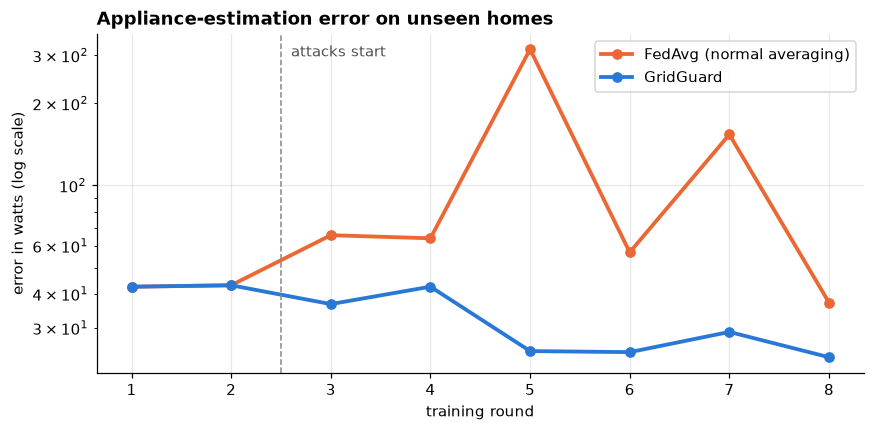

round,1,2,3,4,5,6,7,8
strategy,,,,,,,,
FedAvg,42.5,43.0,65.7,64.0,316.0,56.8,153.8,37.2
GridGuard,42.5,43.0,36.7,42.5,24.7,24.5,29.0,23.4


In [10]:
results = pd.DataFrame(history).pivot(index="round", columns="strategy", values="error_w")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(results.index, results["FedAvg"], marker="o", color="#eb6834", lw=2.5, label="FedAvg (normal averaging)")
ax.plot(results.index, results["GridGuard"], marker="o", color="#2a78d6", lw=2.5, label="GridGuard")
ax.axvline(2.5, color="#898781", ls="--", lw=1)
ax.text(2.6, ax.get_ylim()[1] * 0.9, "attacks start", color="#52514e")
ax.set_yscale("log")
ax.set_xlabel("training round")
ax.set_ylabel("error in watts (log scale)")
ax.legend()
ax.set_title("Appliance-estimation error on unseen homes", loc="left", fontweight="bold")
plt.show()
results.round(1).T

### What GridGuard decided for every home in every round

Hover is not available in a notebook, so every cell carries a short code: **OK** benign, **CH** genuine change (accepted at half weight), **FX** meter fault (quarantined), **AT** attack (rejected), **SIG** bad signature (rejected), **?** unsure (held back).

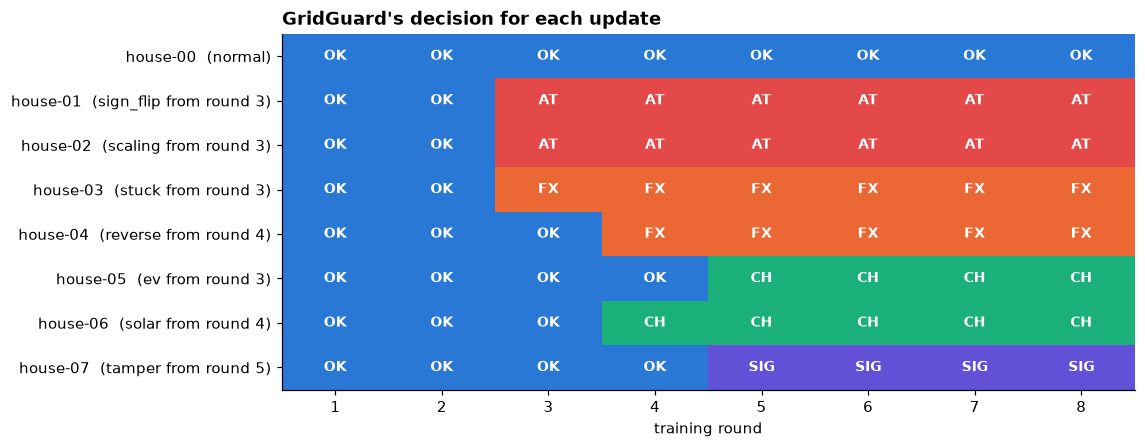

In [11]:
table = pd.DataFrame(decisions)
order = ["benign", "genuine_change", "meter_fault", "malicious", "bad_signature", "uncertain"]
colors = ["#2a78d6", "#1baf7a", "#eb6834", "#e34948", "#6250d6", "#898781"]
short = {"benign": "OK", "genuine_change": "CH", "meter_fault": "FX", "malicious": "AT", "bad_signature": "SIG", "uncertain": "?"}
grid = table.pivot(index="home", columns="round", values="cause")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.imshow(grid.replace({c: i for i, c in enumerate(order)}).astype(float).values, cmap=ListedColormap(colors), vmin=0, vmax=len(order) - 1, aspect="auto")
for (row, col), value in np.ndenumerate(grid.values):
    ax.text(col, row, short[value], ha="center", va="center", color="white", fontweight="bold", fontsize=9)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), [f"{h}  ({SCENARIO[h][1]} from round {SCENARIO[h][2]})" if h in SCENARIO else f"{h}  (normal)" for h in grid.index])
ax.set_xlabel("training round")
ax.grid(False)
ax.set_title("GridGuard's decision for each update", loc="left", fontweight="bold")
plt.show()

In [12]:
def truth(home, r):
    category, _, start = SCENARIO.get(home, (None, None, 1))
    return TRUTH[category] if category and r >= start else "benign"


table["truth"] = [truth(h, r) for h, r in zip(table["home"], table["round"])]
found = table["cause"].replace({"bad_signature": "malicious"})
summary = {
    "FedAvg final error (W)": round(results["FedAvg"].iloc[-1], 1),
    "GridGuard final error (W)": round(results["GridGuard"].iloc[-1], 1),
    "causes identified correctly": f"{(found == table['truth']).mean():.0%}",
    "attacks blocked": f"{(table[table.truth == 'malicious'].weight == 0).mean():.0%}",
    "faulty meters quarantined": f"{(table[table.truth == 'meter_fault'].cause == 'meter_fault').mean():.0%}",
    "honest homes wrongly excluded": f"{table[table.truth.isin(['benign', 'genuine_change'])].cause.isin(['malicious', 'meter_fault', 'bad_signature']).mean():.0%}",
}
pd.Series(summary, name="result").to_frame()

,result
FedAvg final error (W),37.2
GridGuard final error (W),23.4
causes identified correctly,97%
attacks blocked,100%
faulty meters quarantined,100%
honest homes wrongly excluded,0%


### Trust at the end

Attackers lose *integrity* until they are ignored. Faulty meters lose *reliability* but keep their integrity, because the family did nothing wrong. Homes with an EV or solar gain *adaptability*.

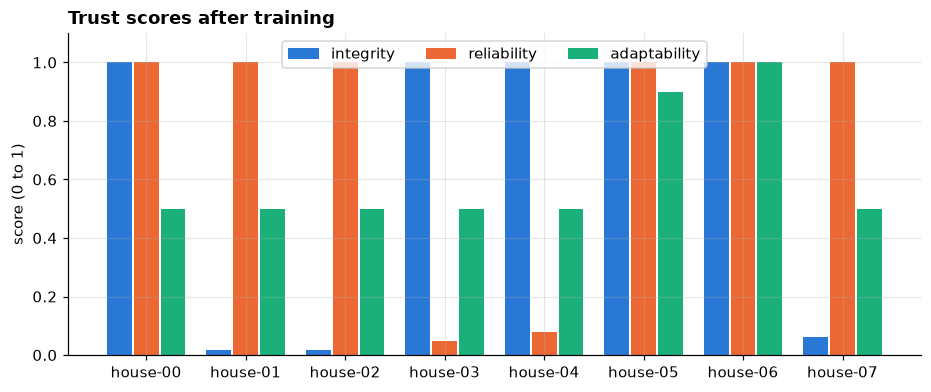

In [13]:
scores = pd.DataFrame(trust).T
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(scores))
for i, (column, color) in enumerate(zip(scores.columns, ["#2a78d6", "#eb6834", "#1baf7a"])):
    ax.bar(x + (i - 1) * 0.27, scores[column], width=0.25, color=color, label=column)
ax.set_xticks(x, scores.index)
ax.set_ylim(0, 1.1)
ax.set_ylabel("score (0 to 1)")
ax.legend(ncol=3, loc="upper center")
ax.set_title("Trust scores after training", loc="left", fontweight="bold")
plt.show()

### Tamper-proof audit chain

The chain verifies. Now we secretly change one old decision, as a dishonest operator might, and verify again.

In [14]:
print("chain intact before editing:", chain.first_broken() is None)
target = next(r for r in chain.records if r["entry"]["home"] == "house-01" and r["entry"]["cause"] == "malicious")
target["entry"]["cause"] = "benign"
print(f"record {target['index']} changed from 'malicious' to 'benign'")
print("first broken record found by the check:", chain.first_broken())
target["entry"]["cause"] = "malicious"
print("after undoing the edit, chain intact:", chain.first_broken() is None)

chain intact before editing: True
record 17 changed from 'malicious' to 'benign'
first broken record found by the check: 17
after undoing the edit, chain intact: True


## Conclusion

- Plain **FedAvg** let three attackers wreck the shared model.
- **GridGuard** looked at the evidence first. It rejected the attacks, quarantined the broken meters without blaming their owners, and still learned from the homes that bought an EV or solar panels.
- **Signatures** caught the update that was changed in transit, and the **audit chain** caught a secret edit of the decision log.
- The same meter evidence is computed live by **Node-RED** in notebook 1, so a real deployment would let the IoT gateway send these numbers along with each update.